**<h3 style="color:orange">Please make sure any LLM coding assistant like Github Copilot or Cursus is turned OFF!</h2>**

**<h4 style="color:orange">We want you to learn and think critically, not to let LLMs do your work for you.</h4>**

**<h4 style="color:orange">Ask your group members or the internet for help, BEFORE asking your favorite chatbot.</h4>**

<img src="../figures/copilot.png">

# Assignment 1 Part 2: Modelling Boids as a Lagrangian System


In [1]:
# Import all the required libraries here
import os
import pickle
import base64
from pathlib import Path
from datetime import datetime

import numpy as np
import torch as T
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader as GraphDataLoader
from torch_geometric.utils import to_dense_batch
import lightning as L
from lightning.pytorch.callbacks import ModelCheckpoint, EarlyStopping
import matplotlib.pyplot as plt
from matplotlib import animation
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from IPython.display import HTML, display


print(f"Success! Running PyTorch {T.__version__} and Lightning {L.__version__}")
cuda_available = T.cuda.is_available()
if cuda_available:
    print(f"CUDA is available! Device count: {T.cuda.device_count()}")
else:
    print("CUDA is not available.")

# ---------------------------------------------------------------------------
# Experiment settings
# ---------------------------------------------------------------------------
K, LENGTH_SCALE = 10, 5.0     # kNN graph size and length scale for distance features
NOISE_STD_VEL = 0.12          # Gaussian velocity noise on TRAINING inputs only
USE_WALLS = True              # learned wall-interaction branch
DOMAIN_SIZE = 25.0            # inferred box size used for the wall features
HIDDEN_DIM, N_LAYERS = 32, 4
BATCH_SIZE, MAX_EPOCHS = 32, 10
LEARNING_RATE, RAW_LOSS_WEIGHT = 1e-3, 0.1
TRAIN_SPLIT, VAL_SPLIT = 0.8, 0.1
SEED = 42
EVAL_SPLIT = "test"            # switch this to "test" only once all model choices are final
EVAL_BATCH_SIZE = 8           # batch size (in simulations) for autoregressive rollouts
VAL_ROLLOUT_COUNT = 32        # fixed validation simulations used for checkpoint selection
EARLY_STOP_PATIENCE = 4       # validation checks (one per epoch)
EARLY_STOP_MIN_DELTA = 1e-3   # in displacement units
RUN_DIAGNOSTICS = True        # one-step metrics + clamp ON/OFF rollout on all validation sims
MAKE_GIFS = True
ACCELERATOR = "auto"          # "auto", "gpu", "mps" or "cpu"
RUNS_DIR = Path.cwd() / "boids_incremental_runs"

# Explicit device for evaluation outside of the Trainer
if ACCELERATOR == "auto":
    device = T.device("cuda" if T.cuda.is_available() else
                      "mps" if T.backends.mps.is_available() else "cpu")
else:
    device = T.device("cuda" if ACCELERATOR in {"gpu", "cuda"} else ACCELERATOR)
print("Evaluation device:", device)

L.seed_everything(SEED, workers=True)

c:\Users\micha\2AMM40\ml4sci-2026\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Seed set to 42


Success! Running PyTorch 2.6.0+cu124 and Lightning 2.6.6
CUDA is available! Device count: 1
Evaluation device: cuda


42

In [2]:

def build_graph(pos, vel, k=K, length_scale=LENGTH_SCALE, batch=None):
    """kNN graph with invariant node and edge features.

    pos, vel: (N, 3). batch: (N,) simulation index per boid, so edges never
    cross simulations. Returns x = [pos, vel, 4 node features], edge_index, edge_attr.
    """
    n = pos.shape[0]
    if batch is None:
        batch = T.zeros(n, dtype=T.long, device=pos.device)
    _, counts = T.unique(batch, return_counts=True)
    if k < 1 or counts.numel() == 0 or counts.min().item() <= k:
        raise ValueError("Each simulation must have more than k particles.")
    if length_scale <= 0:
        raise ValueError("length_scale must be positive.")
    dist = T.cdist(pos, pos)
    dist = dist.masked_fill(batch[:, None] != batch[None, :], float("inf"))
    dist.fill_diagonal_(float("inf"))
    knn_dist, knn_idx = dist.topk(k, dim=-1, largest=False)
    src = knn_idx.reshape(-1)
    dst = T.arange(n, device=pos.device).repeat_interleave(k)
    edge_index = T.stack([src, dst])

    mean_pos = pos[knn_idx].mean(dim=1)
    mean_vel = vel[knn_idx].mean(dim=1)
    node_features = T.cat([
        vel.norm(dim=-1, keepdim=True),
        knn_dist.mean(dim=-1, keepdim=True) / length_scale,
        F.cosine_similarity(vel, mean_vel, dim=-1).unsqueeze(-1),
        (pos - mean_pos).norm(dim=-1, keepdim=True) / length_scale,
    ], dim=-1)
    x = T.cat([pos, vel, node_features], dim=-1)
    rel_pos = pos[src] - pos[dst]
    distance = rel_pos.norm(dim=-1, keepdim=True)
    distance_attr = 1.0 / distance.clamp_min(0.1)  # inverse distance, bounded by 10
    edge_attr = T.cat([
        distance_attr,
        F.cosine_similarity(vel[src], vel[dst], dim=-1).unsqueeze(-1),
        F.cosine_similarity(vel[dst], rel_pos, dim=-1).unsqueeze(-1),
        (vel[src] - vel[dst]).norm(dim=-1, keepdim=True),
    ], dim=-1)
    return x, edge_index, edge_attr


class BoidsDataset(Dataset):
    """Dataset for the Boids simulation data.

    nodes has shape (simulations, states, boids, 6) = [position, velocity], where the
    velocity is the finite difference x_t - x_{t-1} (so the first raw frame is dropped).
    Graphs are built on the fly, so training velocity noise also affects the kNN features.
    Train/val/test sets are views (subset) on the same unmodified tensor.
    """

    def __init__(self, path, k=K, length_scale=LENGTH_SCALE, noise_std_vel=0.0):
        self.path = path
        self.nodes = T.tensor([], dtype=T.float32)
        self.k, self.length_scale = k, length_scale
        self.noise_std_vel = float(noise_std_vel)
        self.sim_ids = []
        self.n_simulations = 0
        self.traj_length = 0

    def load_data(self):
        if self.nodes.numel() > 0:
            return  # already loaded (Lightning calls prepare_data again inside fit/predict)
        if not os.path.exists(self.path):
            raise FileNotFoundError(
                f"Data file not found at {self.path}. Please check the path and try again."
            )
        with open(self.path, "rb") as f:
            data = pickle.load(f)

        positions = T.from_numpy(np.stack(data)).float()
        if positions.ndim != 4 or positions.shape[-1] != 3 or positions.shape[1] < 3:
            raise ValueError("Expected positions with shape (simulations, T>=3, boids, 3).")
        velocities = T.diff(positions, dim=1)
        self.nodes = T.cat([positions[:, 1:], velocities], dim=-1)
        self.sim_ids = list(range(self.nodes.shape[0]))
        self.n_simulations = len(self.sim_ids)
        self.traj_length = self.nodes.shape[1]

        print(
            f"\nLoaded data from {self.path}, containing {len(data)} samples of shape {data[0].shape}\n"
        )
        print("States (simulations, states, boids, [pos, vel]):", tuple(self.nodes.shape))

    def subset(self, sim_ids, noise_std_vel=0.0, as_type=None):
        """View on a subset of simulations, sharing the same tensor (no copy)."""
        cls = as_type or type(self)
        view = cls.__new__(cls)
        view.__dict__.update(self.__dict__)
        view.sim_ids = list(sim_ids)
        view.n_simulations = len(view.sim_ids)
        view.noise_std_vel = float(noise_std_vel)
        return view


class BoidsTrajectoryDataset(BoidsDataset):
    """One sample = one full trajectory: x has shape (boids, traj_len, 6)."""

    def __len__(self):
        return self.n_simulations

    def __getitem__(self, idx):
        # Boids along dim 0 so PyG concatenates the boids of several simulations
        return Data(x=self.nodes[self.sim_ids[idx]].transpose(0, 1))


class BoidsStepDataset(BoidsDataset):
    """One sample = one transition t -> t+1: a kNN graph at t, target = clean velocity at t+1."""

    def __len__(self):
        return self.n_simulations * (self.traj_length - 1)

    def __getitem__(self, idx):
        sim_idx, t_idx = divmod(idx, self.traj_length - 1)
        sim = self.sim_ids[sim_idx]
        state, next_state = self.nodes[sim, t_idx], self.nodes[sim, t_idx + 1]
        pos, vel = state[:, :3], state[:, 3:6]
        if self.noise_std_vel > 0:
            # Out-of-place: never modify the shared clean state tensor
            vel = vel + self.noise_std_vel * T.randn_like(vel)
        x, edge_index, edge_attr = build_graph(pos, vel, self.k, self.length_scale)
        # Predict the next VELOCITY, so the target stays clean. No position noise.
        return Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=next_state[:, 3:6])


class DataModule(L.LightningDataModule):
    """Lightning DataModule class that manages the dataset splitting and the dataloaders"""

    def __init__(self, dataset, batch_size=BATCH_SIZE, train_split=TRAIN_SPLIT,
                 val_split=VAL_SPLIT, seed=SEED, noise_std_vel=NOISE_STD_VEL,
                 eval_split=EVAL_SPLIT):
        super().__init__()
        self.dataset = dataset
        self.batch_size = batch_size
        self.train_split = train_split
        self.val_split = val_split
        self.seed = seed
        self.noise_std_vel = noise_std_vel
        if eval_split not in {"val", "test"}:
            raise ValueError("eval_split must be 'val' or 'test'.")
        self.eval_split = eval_split

    def prepare_data(self):
        self.dataset.load_data()

    def setup(self, stage=None):
        if getattr(self, "train_set", None) is not None:
            return

        self.dataset.load_data()  # no-op if prepare_data already ran
        n = self.dataset.n_simulations
        nt, nv = int(n * self.train_split), int(n * self.val_split)
        if not (0 < nt < nt + nv < n):
            raise ValueError("Train, validation and test must all be nonempty.")
        # Split whole trajectories, keeping the original simulation order
        self.train_ids = list(range(nt))
        self.val_ids = list(range(nt, nt + nv))
        self.test_ids = list(range(nt + nv, n))
        self.train_set = self.dataset.subset(self.train_ids, noise_std_vel=self.noise_std_vel)
        self.val_set = self.dataset.subset(self.val_ids, noise_std_vel=0.0)
        self.test_set = self.dataset.subset(self.test_ids, noise_std_vel=0.0)

    def train_dataloader(self):
        return GraphDataLoader(self.train_set, batch_size=self.batch_size, shuffle=True,
                               generator=T.Generator().manual_seed(self.seed), num_workers=0)

    def val_dataloader(self):
        return GraphDataLoader(self.val_set, batch_size=self.batch_size, shuffle=False)

    def test_dataloader(self):
        return GraphDataLoader(self.test_set, batch_size=self.batch_size, shuffle=False)

    def predict_dataloader(self):
        eval_set = self.val_set if self.eval_split == "val" else self.test_set
        return GraphDataLoader(eval_set, batch_size=self.batch_size, shuffle=False)

path = os.path.join(os.getcwd(), "..", "data", "boids_dataset.pkl")
boids_dataset = BoidsTrajectoryDataset(path=path)
boids_dataset.load_data()


Loaded data from c:\Users\micha\2AMM40\ml4sci-2026\assignments\..\data\boids_dataset.pkl, containing 2000 samples of shape (50, 100, 3)

States (simulations, states, boids, [pos, vel]): (2000, 49, 100, 6)


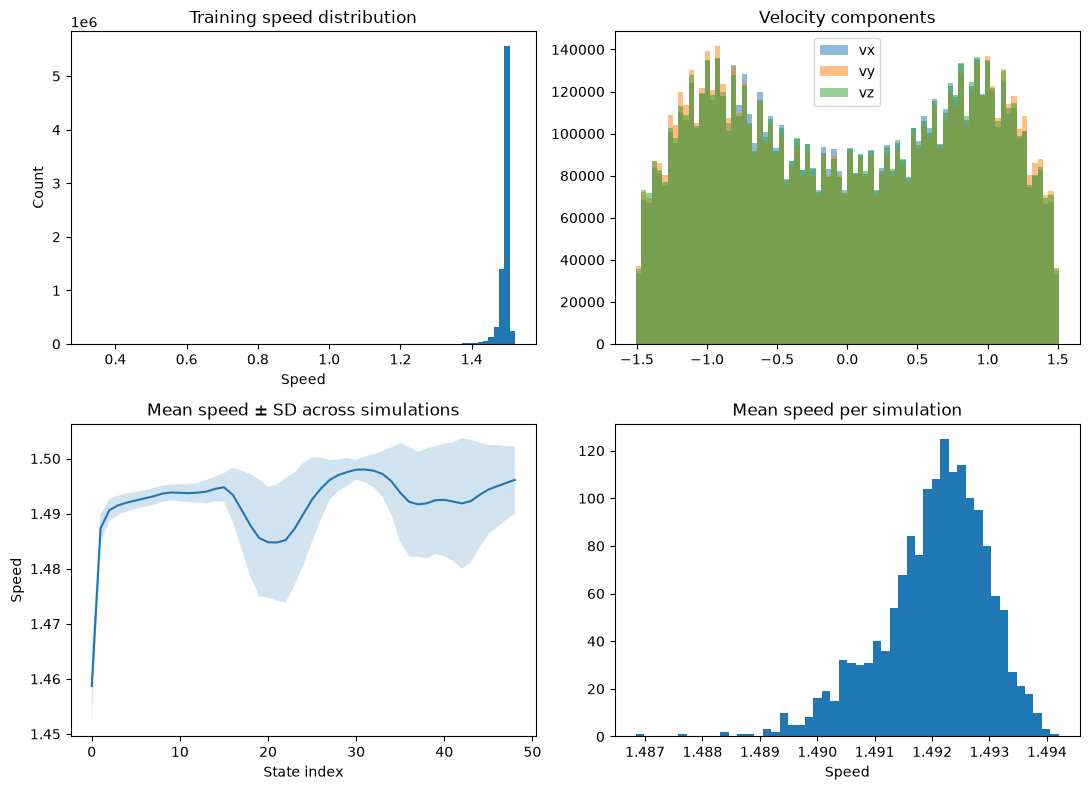

Speed: mean=1.4920, std=0.0204, min=0.3337, max=1.5209
vx: mean=0.0016, std=0.8549
vy: mean=-0.0025, std=0.8685
vz: mean=0.0033, std=0.8610
r=2.0: mean=17.1 | early(t<5)=1.3 | late(t>=40)=30.1 | isolated=5.9%
r=3.0: mean=29.0 | early(t<5)=2.6 | late(t>=40)=47.5 | isolated=2.4%
r=4.0: mean=34.6 | early(t<5)=4.0 | late(t>=40)=52.8 | isolated=1.2%
r=5.0: mean=38.0 | early(t<5)=5.8 | late(t>=40)=54.4 | isolated=0.6%
r=6.0: mean=41.2 | early(t<5)=8.2 | late(t>=40)=55.8 | isolated=0.3%
r=7.0: mean=44.7 | early(t<5)=11.3 | late(t>=40)=57.4 | isolated=0.2%


In [3]:

# Exploratory data analysis on the clean TRAINING simulations only
n_train = int(boids_dataset.n_simulations * TRAIN_SPLIT)  # same split as the DataModule
train_nodes = boids_dataset.nodes[:n_train]
velocities = train_nodes[..., 3:6]
speed = velocities.norm(dim=-1)
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes[0, 0].hist(speed.flatten().numpy(), bins=80)
axes[0, 0].set(title="Training speed distribution", xlabel="Speed", ylabel="Count")
for i, label in enumerate(["vx", "vy", "vz"]):
    axes[0, 1].hist(velocities[..., i].flatten().numpy(), bins=80, alpha=.5, label=label)
axes[0, 1].set_title("Velocity components"); axes[0, 1].legend()
# Dispersion BETWEEN simulation means, separately at each timestep
per_sim_speed = speed.mean(dim=2)
mean_speed = per_sim_speed.mean(dim=0)
std_speed = per_sim_speed.std(dim=0, unbiased=False)
t = np.arange(len(mean_speed))
axes[1, 0].plot(t, mean_speed.numpy())
axes[1, 0].fill_between(t, (mean_speed-std_speed).numpy(),
                        (mean_speed+std_speed).numpy(), alpha=.2)
axes[1, 0].set(title="Mean speed ± SD across simulations", xlabel="State index", ylabel="Speed")
axes[1, 1].hist(speed.mean(dim=(1, 2)).numpy(), bins=50)
axes[1, 1].set(title="Mean speed per simulation", xlabel="Speed")
plt.tight_layout(); plt.show()
print(f"Speed: mean={speed.mean():.4f}, std={speed.std():.4f}, "
      f"min={speed.min():.4f}, max={speed.max():.4f}")
for i, label in enumerate(["vx", "vy", "vz"]):
    values = velocities[..., i]
    print(f"{label}: mean={values.mean():.4f}, std={values.std():.4f}")

# Neighbourhood degree at several radii (local generator: does not touch the training RNG)
positions = train_nodes[..., :3]
generator = T.Generator().manual_seed(0)
ids = T.randperm(len(positions), generator=generator)[:min(100, len(positions))]
radii = [2., 3., 4., 5., 6., 7.]
degrees = {r: [] for r in radii}
# Chunk the distance calculation to avoid one huge pairwise-distance tensor
for chunk_ids in ids.split(10):
    sample = positions[chunk_ids]
    n_sample, trajectory_length, n_boids, _ = sample.shape
    flat = sample.reshape(-1, n_boids, 3)
    distances = T.cdist(flat, flat)
    distances.diagonal(dim1=-2, dim2=-1).fill_(float("inf"))
    for r in radii:
        degrees[r].append((distances < r).sum(-1).float().reshape(
            n_sample, trajectory_length, n_boids))
for r in radii:
    degree = T.cat(degrees[r])
    late = degree[:, 40:]
    late_mean = float(late.mean()) if late.numel() else float("nan")
    print(f"r={r}: mean={degree.mean():.1f} | early(t<5)={degree[:, :5].mean():.1f} | "
          f"late(t>=40)={late_mean:.1f} | isolated={(degree == 0).float().mean()*100:.1f}%")
    


In [ ]:
class EGNNLayer(nn.Module):
    """One equivariant message-passing step, based on the practical's layer.
    Changes for the boids: an extra alignment term in the velocity update
    (steer towards the neighbours' velocities), squared distance normalized
    by a length scale, and mean aggregation over the number of neighbours
    of each node (kNN graph instead of fully connected)."""

    def __init__(self, node_dim, edge_dim, hidden_dim, dist_norm=1.0, C=1.0):
        super().__init__()
        self.C = C
        self.dist_norm = dist_norm

        # m_ij = phi_e(h_i, h_j, ||x_i - x_j||^2 / length_scale^2, edge_attr)
        self.edge_mlp = nn.Sequential(
            nn.Linear(2 * node_dim + 1 + edge_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
        )

        # phi_v(h_i): scalar gate for how much of the previous velocity to keep
        self.velocity_mlp = nn.Sequential(
            nn.Linear(node_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 1),
        )

        # phi_x(m_ij): scalar weight along the relative position (separation / cohesion)
        self.coord_mlp = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 1, bias=False),
        )
        # Small init so the model doesn't produce huge displacements at the start of training
        T.nn.init.xavier_uniform_(self.coord_mlp[-1].weight, gain=0.001)

        # phi_a(m_ij): scalar weight along the relative velocity (alignment)
        self.align_mlp = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 1, bias=False),
        )
        T.nn.init.xavier_uniform_(self.align_mlp[-1].weight, gain=0.001)

        # phi_h(h_i, mean_j m_ij)
        self.node_mlp = nn.Sequential(
            nn.Linear(node_dim + hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, node_dim),
        )

    def forward(self, h, pos, vel, edge_index, edge_attr=None):
        src, dst = edge_index

        # Squared distance is invariant to rotation/translation - this is the
        # only geometric info allowed into the invariant message computation.
        rel = pos[src] - pos[dst]
        dist2 = (rel ** 2).sum(dim=-1, keepdim=True) / self.dist_norm

        if edge_attr is None:
            edge_attr = pos.new_zeros(src.shape[0], 0)

        m = self.edge_mlp(T.cat([h[src], h[dst], dist2, edge_attr], dim=-1))

        # Number of neighbours of each node (always k with kNN, but computed
        # per node so the layer also works with any other graph)
        degree = h.new_zeros(h.shape[0]).index_add_(0, dst, h.new_ones(dst.shape[0]))
        degree = degree.clamp(min=1).unsqueeze(-1)

        # mean incoming messages per node
        agg = h.new_zeros(h.shape[0], m.shape[-1])
        agg.index_add_(0, dst, m)
        agg = agg / degree

        h_new = self.node_mlp(T.cat([h, agg], dim=-1))

        # Equivariant velocity update: scale previous velocity + mean over the
        # neighbours of two vector terms, one per boid rule:
        #   relative position * phi_x -> separation / cohesion
        #   relative velocity * phi_a -> alignment (both vectors rotate with the
        #   system, so equivariance holds exactly like in the proof)
        velocity_scale = self.velocity_mlp(h)
        dv_pos = rel * self.coord_mlp(m)
        dv_vel = (vel[src] - vel[dst]) * self.align_mlp(m)
        interaction = vel.new_zeros(vel.shape)
        interaction.index_add_(0, dst, dv_pos + dv_vel)
        interaction = interaction / degree
        vel_new = velocity_scale * vel + self.C * interaction

        pos_new = pos + vel_new

        return h_new, pos_new, vel_new


class EGNN(nn.Module):
    """EGNN for boids: equivariant layers + learned wall correction + speed projection.

    Input x = [pos (3), vel (3), invariant node features (4)]; output = next velocity.
    max_speed should be the maximum training speed (computed from the train split).
    """

    def __init__(self, input_dim=4, hidden_dim=HIDDEN_DIM, edge_dim=4, length_scale=LENGTH_SCALE,
                 n_layers=N_LAYERS, max_speed=1.52, use_walls=USE_WALLS, domain_size=DOMAIN_SIZE):
        super().__init__()
        self.node_in = nn.Linear(input_dim, hidden_dim)
        self.layers = nn.ModuleList([
            EGNNLayer(hidden_dim, edge_dim, hidden_dim, dist_norm=length_scale**2)
            for _ in range(n_layers)])
        self.length_scale, self.use_walls = length_scale, use_walls
        self.register_buffer("speed_limit", T.tensor(float(max_speed)))
        self.register_buffer("wall_normals", T.cat([T.eye(3), -T.eye(3)]))
        self.register_buffer("wall_points", T.cat([
            T.zeros(3, 3), T.full((3, 3), float(domain_size))]))
        self.wall_mlp = nn.Sequential(
            nn.Linear(4, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.SiLU(), nn.Linear(hidden_dim, 1))
        nn.init.zeros_(self.wall_mlp[-1].weight)
        nn.init.zeros_(self.wall_mlp[-1].bias)

    def wall_delta(self, x):
        # These are physical input coordinates and velocities, not intermediate layer coordinates.
        pos, vel = x[:, :3], x[:, 3:6]
        distances = ((pos[:, None] - self.wall_points[None]) *
                     self.wall_normals[None]).sum(-1) / self.length_scale
        normal_velocity = vel @ self.wall_normals.T
        speed = vel.norm(dim=-1, keepdim=True).expand_as(distances)
        features = T.stack([distances, distances.square(), normal_velocity, speed], dim=-1)
        coefficients = self.wall_mlp(features).squeeze(-1)
        # Learned correction; its sign is not prescribed as an exact simulator rule.
        # E(3) equivariance requires transforming walls together with particles.
        return coefficients @ self.wall_normals

    def raw_velocity(self, x, edge_index, edge_attr=None):
        pos, vel = x[:, :3], x[:, 3:6]
        h = self.node_in(x[:, 6:])
        for layer in self.layers:
            h, pos, vel = layer(h, pos, vel, edge_index, edge_attr)
        if self.use_walls:
            vel = vel + self.wall_delta(x)
        return vel

    def project_velocity(self, velocity):
        speed = velocity.norm(dim=-1, keepdim=True).clamp_min(1e-8)
        return velocity * (self.speed_limit / speed).clamp(max=1.)

    def forward(self, x, edge_index, edge_attr=None):
        return self.project_velocity(self.raw_velocity(x, edge_index, edge_attr))
    


In [5]:
class BoidsModel(L.LightningModule):
    def __init__(self, model, learning_rate=LEARNING_RATE, raw_loss_weight=RAW_LOSS_WEIGHT,
                 k=K, length_scale=LENGTH_SCALE):
        super().__init__()
        self.model = model
        self.learning_rate = learning_rate
        self.raw_loss_weight = raw_loss_weight
        self.k, self.length_scale = k, length_scale
        self.save_hyperparameters(ignore=["model"])

    def forward(self, x, edge_index, edge_attr=None):
        return self.model(x, edge_index, edge_attr)

    def _step(self, batch, prefix):
        # batch.y is the clean NEXT VELOCITY, shape (N, 3)
        raw = self.model.raw_velocity(batch.x, batch.edge_index, batch.edge_attr)
        output = self.model.project_velocity(raw)
        mse = F.mse_loss(output, batch.y)
        raw_mse = F.mse_loss(raw, batch.y)
        cap_fraction = (raw.norm(dim=-1) > self.model.speed_limit).float().mean()
        for key, value in {"loss": mse, "raw_loss": raw_mse, "cap_fraction": cap_fraction}.items():
            self.log(f"{prefix}_{key}", value, on_step=False, on_epoch=True,
                     prog_bar=(key == "loss"), batch_size=batch.num_graphs)
        # Also train the raw magnitudes: clipping alone can hide excessive raw speeds
        return mse + self.raw_loss_weight * raw_mse

    def training_step(self, batch, batch_idx):
        return self._step(batch, "train")

    def validation_step(self, batch, batch_idx):
        return self._step(batch, "val")

    @T.no_grad()
    def rollout_batch(self, batch, clamp=True):
        """Autoregressive rollout from the first state of each trajectory in the batch."""
        seed = batch.x[:, 0, :6]
        current = seed
        states, raw_speeds = [seed], []
        failed = T.zeros(batch.num_graphs, dtype=T.bool, device=seed.device)
        first_bad = T.full((batch.num_graphs,), -1, dtype=T.long, device=seed.device)
        for frame in range(1, batch.x.shape[1]):
            #Rebuild the kNN graph at each step, using the current positions and velocities
            x, edge, attr = build_graph(current[:, :3], current[:, 3:6],
                                        self.k, self.length_scale, batch.batch)
            raw = self.model.raw_velocity(x, edge, attr)
            vel = self.model.project_velocity(raw) if clamp else raw
            next_state = T.cat([current[:, :3] + vel, vel], dim=-1)
            raw_speed = raw.norm(dim=-1)
            bad_nodes = (~T.isfinite(next_state).all(-1) | ~T.isfinite(raw).all(-1)
                         | ~T.isfinite(raw_speed))
            bad_count = T.zeros(batch.num_graphs, dtype=T.float32, device=seed.device)
            bad_count.index_add_(0, batch.batch, bad_nodes.float())
            newly_failed = (bad_count > 0) & ~failed
            first_bad[newly_failed] = frame
            failed = failed | newly_failed
            mask = failed[batch.batch]
            states.append(next_state.masked_fill(mask[:, None], float("nan")))
            raw_speeds.append(raw_speed.masked_fill(mask, float("nan")))
            # Failed graphs keep a finite dummy state internally so other simulations
            # can finish. Their exported states stay NaN and the failure is reported.
            current = T.where(mask[:, None], seed, next_state)
        dense, _ = to_dense_batch(T.stack(states, dim=1), batch.batch)
        raw_dense, _ = to_dense_batch(T.stack(raw_speeds, dim=1), batch.batch)
        return {"states": dense.cpu(), "raw_speeds": raw_dense.cpu(),
                "first_bad_frame": first_bad.cpu()}

    def predict_step(self, batch, batch_idx):
        return self.rollout_batch(batch, clamp=True)

    def configure_optimizers(self):
        return T.optim.Adam(self.parameters(), lr=self.learning_rate)

class LossHistory(L.Callback):
    def __init__(self):
        self.train_loss, self.val_loss = [], []
    def on_train_epoch_end(self, trainer, pl_module):
        value = trainer.callback_metrics.get("train_loss")
        if value is not None:
            self.train_loss.append(float(value))
    def on_validation_epoch_end(self, trainer, pl_module):
        if trainer.sanity_checking:
            return
        value = trainer.callback_metrics.get("val_loss")
        if value is not None:
            self.val_loss.append(float(value))


class ValidationRollout(L.Callback):
    """Select checkpoints on the rollout ADE of a fixed validation subset, never on test."""
    def __init__(self, trajectory_dataset, batch_size=EVAL_BATCH_SIZE):
        self.loader = GraphDataLoader(trajectory_dataset, batch_size=batch_size, shuffle=False)
        self.history = []

    @T.no_grad()
    def score(self, pl_module):
        was_training = pl_module.training
        pl_module.eval()
        try:
            return self._score(pl_module)
        finally:
            pl_module.train(was_training)

    def _score(self, pl_module):
        total_error, count, failed = 0., 0, 0
        for batch in self.loader:
            batch = batch.to(pl_module.device)
            result = pl_module.rollout_batch(batch, clamp=True)
            truth, _ = to_dense_batch(batch.x[..., :3], batch.batch)
            error = (result["states"][..., :3].double() - truth.cpu().double()).norm(dim=-1)
            failed += int((result["first_bad_frame"] >= 0).sum())
            total_error += float(error[:, :, 1:].sum())
            count += error[:, :, 1:].numel()
        return float("inf") if failed else total_error / count

    def on_validation_epoch_end(self, trainer, pl_module):
        if trainer.sanity_checking:
            return
        ade = self.score(pl_module)
        pl_module.log("val_rollout_ade", ade, on_step=False, on_epoch=True,
                      prog_bar=True, batch_size=len(self.loader.dataset))
        self.history.append((trainer.current_epoch, ade))


@T.inference_mode()
def collect_rollouts(model, loader, clamp=True):
    """Return all selected simulations in loader order. Do not shuffle the loader."""
    was_training = model.training
    model.eval()
    results = []
    try:
        for batch in loader:
            results.append(model.rollout_batch(batch.to(model.device), clamp=clamp))
    finally:
        model.train(was_training)
    return {key: T.cat([r[key] for r in results]).numpy() for key in results[0]}


def rollout_report(result, truth_states, speed_limit):
    # Rollouts are (S, N, T, 6), while the clean states are (S, T, N, 6)
    states = result["states"].transpose(0, 2, 1, 3).astype(np.float64)
    truth = np.asarray(truth_states, dtype=np.float64)
    if states.shape != truth.shape:
        raise ValueError("Prediction and truth shapes/order must agree.")
    bad = result["first_bad_frame"] >= 0
    raw = result["raw_speeds"].transpose(0, 2, 1).astype(np.float64)
    report = {"n_trajectories": len(states), "diverged": int(bad.sum()),
              "first_bad_frame": result["first_bad_frame"]}
    # Never silently drop failed trajectories or shorten the evaluation horizon
    if bad.any():
        report.update(ADE=float("inf"), ADE_future=float("inf"), FDE=float("inf"),
                      mean_speed=float("nan"), cap_fraction=float("nan"))
        return report
    error = np.linalg.norm(states[..., :3] - truth[..., :3], axis=-1)
    speed = np.linalg.norm(np.diff(states[..., :3], axis=1), axis=-1)
    report.update(ADE=float(error.mean()), ADE_future=float(error[:, 1:].mean()),
                  FDE=float(error[:, -1].mean()), mean_speed=float(speed.mean()),
                  cap_fraction=float((raw > speed_limit).mean()),
                  speed_by_time=speed.mean(axis=(0, 2)),
                  cap_by_time=(raw > speed_limit).mean(axis=(0, 2)),
                  raw_quantiles=np.percentile(raw, [50, 95, 99]))
    return report


@T.inference_mode()
def diagnose_one_step(model, loader):
    """Clean teacher forcing over the ENTIRE validation step dataset."""
    was_training = model.training
    model.eval()
    totals = dict(raw_mse=0., projected_mse=0., true_speed=0., raw_speed=0.,
                  projected_speed=0., cap_fraction=0.)
    count, cosine_sum, cosine_count = 0, 0., 0
    try:
        for batch in loader:
            batch = batch.to(model.device)
            raw = model.model.raw_velocity(batch.x, batch.edge_index, batch.edge_attr)
            projected = model.model.project_velocity(raw)
            target = batch.y
            if not (T.isfinite(raw).all() and T.isfinite(target).all()):
                raise RuntimeError("Non-finite one-step output/target; inspect checkpoint and features.")
            r, p, g = raw.norm(dim=-1), projected.norm(dim=-1), target.norm(dim=-1)
            totals["raw_mse"] += float((raw-target).square().sum()) / 3
            totals["projected_mse"] += float((projected-target).square().sum()) / 3
            totals["true_speed"] += float(g.sum())
            totals["raw_speed"] += float(r.sum())
            totals["projected_speed"] += float(p.sum())
            totals["cap_fraction"] += float((r > model.model.speed_limit).sum())
            mask = (p > 1e-8) & (g > 1e-8)
            cosine_sum += float(F.cosine_similarity(projected[mask], target[mask]).sum())
            cosine_count += int(mask.sum())
            count += len(target)
    finally:
        model.train(was_training)
    result = {key: value/count for key, value in totals.items()}
    result["speed_bias"] = result["projected_speed"] - result["true_speed"]
    result["direction_cosine"] = cosine_sum/cosine_count if cosine_count else float("nan")
    result["direction_valid_fraction"] = cosine_count/count
    return result


def run_validation_diagnostics(model, dm, batch_size=EVAL_BATCH_SIZE):
    """dm is the (step) DataModule used for training; always uses ALL validation simulations."""
    print("Clean one-step metrics on ALL validation transitions:")
    one_step = diagnose_one_step(model, dm.val_dataloader())
    for key, value in one_step.items():
        print(f"  {key}: {value:.6f}")
    loader = GraphDataLoader(dm.dataset.subset(dm.val_ids, as_type=BoidsTrajectoryDataset),
                             batch_size=batch_size, shuffle=False)
    truth = dm.dataset.nodes[dm.val_ids].numpy()
    limit = float(model.model.speed_limit)
    results, reports = {}, {}
    for label, clamp in [("clamp ON", True), ("clamp OFF", False)]:
        results[label] = collect_rollouts(model, loader, clamp=clamp)
        reports[label] = rollout_report(results[label], truth, limit)
        r = reports[label]
        print(f"{label}: {r['diverged']}/{r['n_trajectories']} diverged | "
              f"ADE_future={r['ADE_future']:.4f} | FDE={r['FDE']:.4f} | "
              f"mean speed={r['mean_speed']:.4f} | raw above limit={r['cap_fraction']:.1%}")
        if r["diverged"]:
            print("  Failed validation simulation IDs and first bad frames:",
                  [(dm.val_ids[i], int(t)) for i, t in enumerate(r["first_bad_frame"]) if t >= 0])
        else:
            print("  Raw speed percentiles [50,95,99]:", r["raw_quantiles"])
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    times = np.arange(1, truth.shape[1])
    axes[0].plot(times, np.linalg.norm(np.diff(truth[..., :3], axis=1), axis=-1).mean(axis=(0, 2)),
                 color="black", label="Truth")
    for label, r in reports.items():
        if r["diverged"]:
            continue
        axes[0].plot(times, r["speed_by_time"], label=label)
        axes[1].plot(times, r["cap_by_time"] * 100, label=label)
    axes[0].set(title="Rollout mean speed", xlabel="Rollout frame", ylabel="Speed")
    axes[1].set(title="Raw predictions above training speed limit",
                xlabel="Rollout frame", ylabel="% of boids")
    for ax in axes:
        ax.legend(); ax.grid(alpha=.2)
    plt.tight_layout(); plt.show()
    return {"one_step": one_step, "reports": reports}


In [ ]:
LOAD_CHECKPOINT = os.path.join(os.getcwd(), "boids_incremental_runs",
    "knn10_inverse_noise0.12_20260925-152259-041300", "best-epoch=07-val_rollout_ade=6.3402.ckpt")

# LOAD_CHECKPOINT = None  # set to a valid path to skip training and load a checkpoint

# Initialize dataset
dataset = BoidsStepDataset(path)

# Initialize datamodule (whole simulations: first 80% train, next 10% val, last 10% test)
datamodule = DataModule(dataset)
datamodule.prepare_data()
datamodule.setup("fit")
MAX_SPEED = float(dataset.nodes[datamodule.train_ids][..., 3:6].norm(dim=-1).max())
print("Train/val/test simulations:", len(datamodule.train_ids),
      len(datamodule.val_ids), len(datamodule.test_ids))
print(f"Speed limit from TRAIN ONLY: {MAX_SPEED:.6f}")

# Initialize model
L.seed_everything(SEED, workers=True)
egnn = EGNN(max_speed=MAX_SPEED)
model = BoidsModel(egnn)
loss_history = LossHistory()

val_generator = T.Generator().manual_seed(SEED)
selection = T.randperm(len(datamodule.val_ids), generator=val_generator)[:VAL_ROLLOUT_COUNT]
monitor_ids = [datamodule.val_ids[i] for i in selection.tolist()]
rollout_validation = ValidationRollout(dataset.subset(monitor_ids, as_type=BoidsTrajectoryDataset))

if LOAD_CHECKPOINT is not None:
    # Evaluate only: load the saved weights, no training
    saved = T.load(LOAD_CHECKPOINT, map_location="cpu", weights_only=False)
    model.load_state_dict(saved["state_dict"])
    print("Loaded checkpoint:", LOAD_CHECKPOINT)
    trainer = L.Trainer(accelerator=ACCELERATOR, devices=1, logger=False)
else:
    run_name = f"knn{K}_inverse_noise{NOISE_STD_VEL:g}_{datetime.now():%Y%m%d-%H%M%S-%f}"
    checkpoint = ModelCheckpoint(dirpath=str(RUNS_DIR / run_name),
        filename="best-{epoch:02d}-{val_rollout_ade:.4f}",
        monitor="val_rollout_ade", mode="min", save_top_k=1, save_last=True,
        save_on_train_epoch_end=False)
    early_stop = EarlyStopping(monitor="val_rollout_ade", mode="min",
        patience=EARLY_STOP_PATIENCE, min_delta=EARLY_STOP_MIN_DELTA,
        check_finite=True, check_on_train_epoch_end=False)
    L.seed_everything(SEED, workers=True)
    trainer = L.Trainer(max_epochs=MAX_EPOCHS, accelerator=ACCELERATOR, devices=1,
                        callbacks=[rollout_validation, loss_history, early_stop, checkpoint],
                        gradient_clip_val=1., logger=False, num_sanity_val_steps=0)
    trainer.fit(model, datamodule=datamodule)
    if not checkpoint.best_model_path:
        raise RuntimeError("No checkpoint was saved; inspect the validation results.")
    best = T.load(checkpoint.best_model_path, map_location="cpu", weights_only=False)
    model.load_state_dict(best["state_dict"])
    print("Best rollout checkpoint:", checkpoint.best_model_path)

# Load the inference dataset
traj_dataset = BoidsTrajectoryDataset(path)
traj_datamodule = DataModule(traj_dataset, batch_size=EVAL_BATCH_SIZE)

# Perform inference
rollouts = trainer.predict(model, datamodule=traj_datamodule)



Loaded data from c:\Users\micha\2AMM40\ml4sci-2026\assignments\..\data\boids_dataset.pkl, containing 2000 samples of shape (50, 100, 3)


Seed set to 42
Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA RTX 1000 Ada Generation Laptop GPU') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]



States (simulations, states, boids, [pos, vel]): (2000, 49, 100, 6)
Train/val/test simulations: 1600 200 200
Speed limit from TRAIN ONLY: 1.520851



  | Name  | Type | Params | Mode  | FLOPs
-----------------------------------------------
0 | model | EGNN | 40.2 K | train | 0    
-----------------------------------------------
40.2 K    Trainable params
0         Non-trainable params
40.2 K    Total params
0.161     Total estimated model params size (MB)
97        Modules in train mode
0         Modules in eval mode
0         Total Flops
c:\Users\micha\2AMM40\ml4sci-2026\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.
c:\Users\micha\2AMM40\ml4sci-2026\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `Da

Epoch 9: 100%|██████████| 2400/2400 [02:55<00:00, 13.69it/s, val_loss=0.00634, val_rollout_ade=6.630, train_loss=0.00869]

`Trainer.fit` stopped: `max_epochs=10` reached.


Epoch 9: 100%|██████████| 2400/2400 [02:55<00:00, 13.69it/s, val_loss=0.00634, val_rollout_ade=6.630, train_loss=0.00869]
Best rollout checkpoint: C:\Users\micha\2AMM40\ml4sci-2026\assignments\boids_incremental_runs\knn10_inverse_noise0.12_20260925-152259-041300\best-epoch=07-val_rollout_ade=6.3402.ckpt


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\micha\2AMM40\ml4sci-2026\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.



Loaded data from c:\Users\micha\2AMM40\ml4sci-2026\assignments\..\data\boids_dataset.pkl, containing 2000 samples of shape (50, 100, 3)

States (simulations, states, boids, [pos, vel]): (2000, 49, 100, 6)
Predicting DataLoader 0: 100%|██████████| 25/25 [00:08<00:00,  2.79it/s]


Evaluating 200 test trajectories (no extra slicing)
Raw rollout speeds above limit: 45.9%
Raw speed percentiles [50,95,99]: [1.51015991 1.73663832 1.95273024]


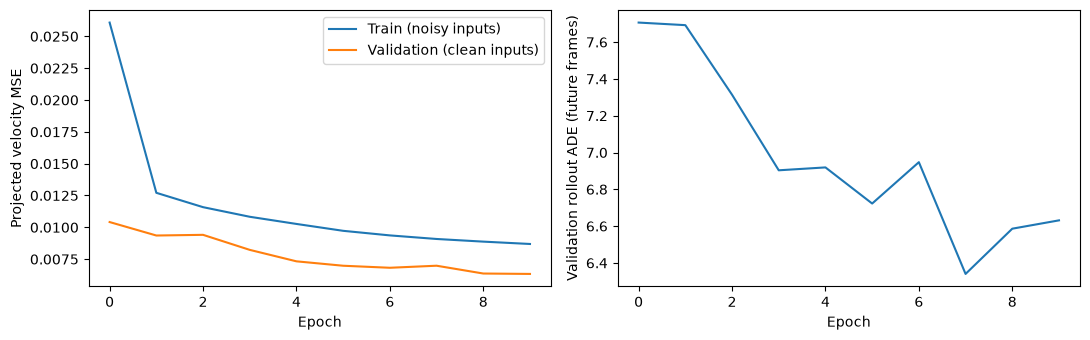

Clean one-step metrics on ALL validation transitions:
  raw_mse: 0.014383
  projected_mse: 0.006985
  true_speed: 1.492685
  raw_speed: 1.550329
  projected_speed: 1.481763
  cap_fraction: 0.583502
  speed_bias: -0.010922
  direction_cosine: 0.996408
  direction_valid_fraction: 1.000000
clamp ON: 0/200 diverged | ADE_future=6.8406 | FDE=10.3479 | mean speed=1.4637 | raw above limit=46.5%
  Raw speed percentiles [50,95,99]: [1.51166624 1.7382849  1.94961894]
clamp OFF: 0/200 diverged | ADE_future=7.2214 | FDE=10.9244 | mean speed=1.5342 | raw above limit=52.1%
  Raw speed percentiles [50,95,99]: [1.52631646 1.77328245 1.98288701]


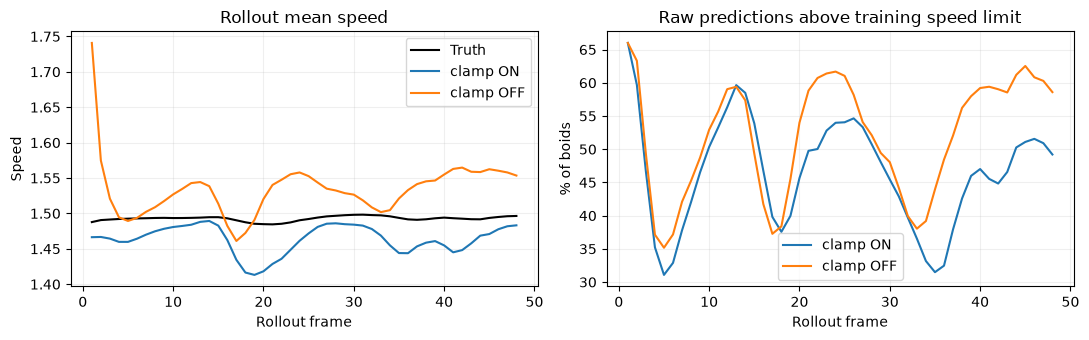

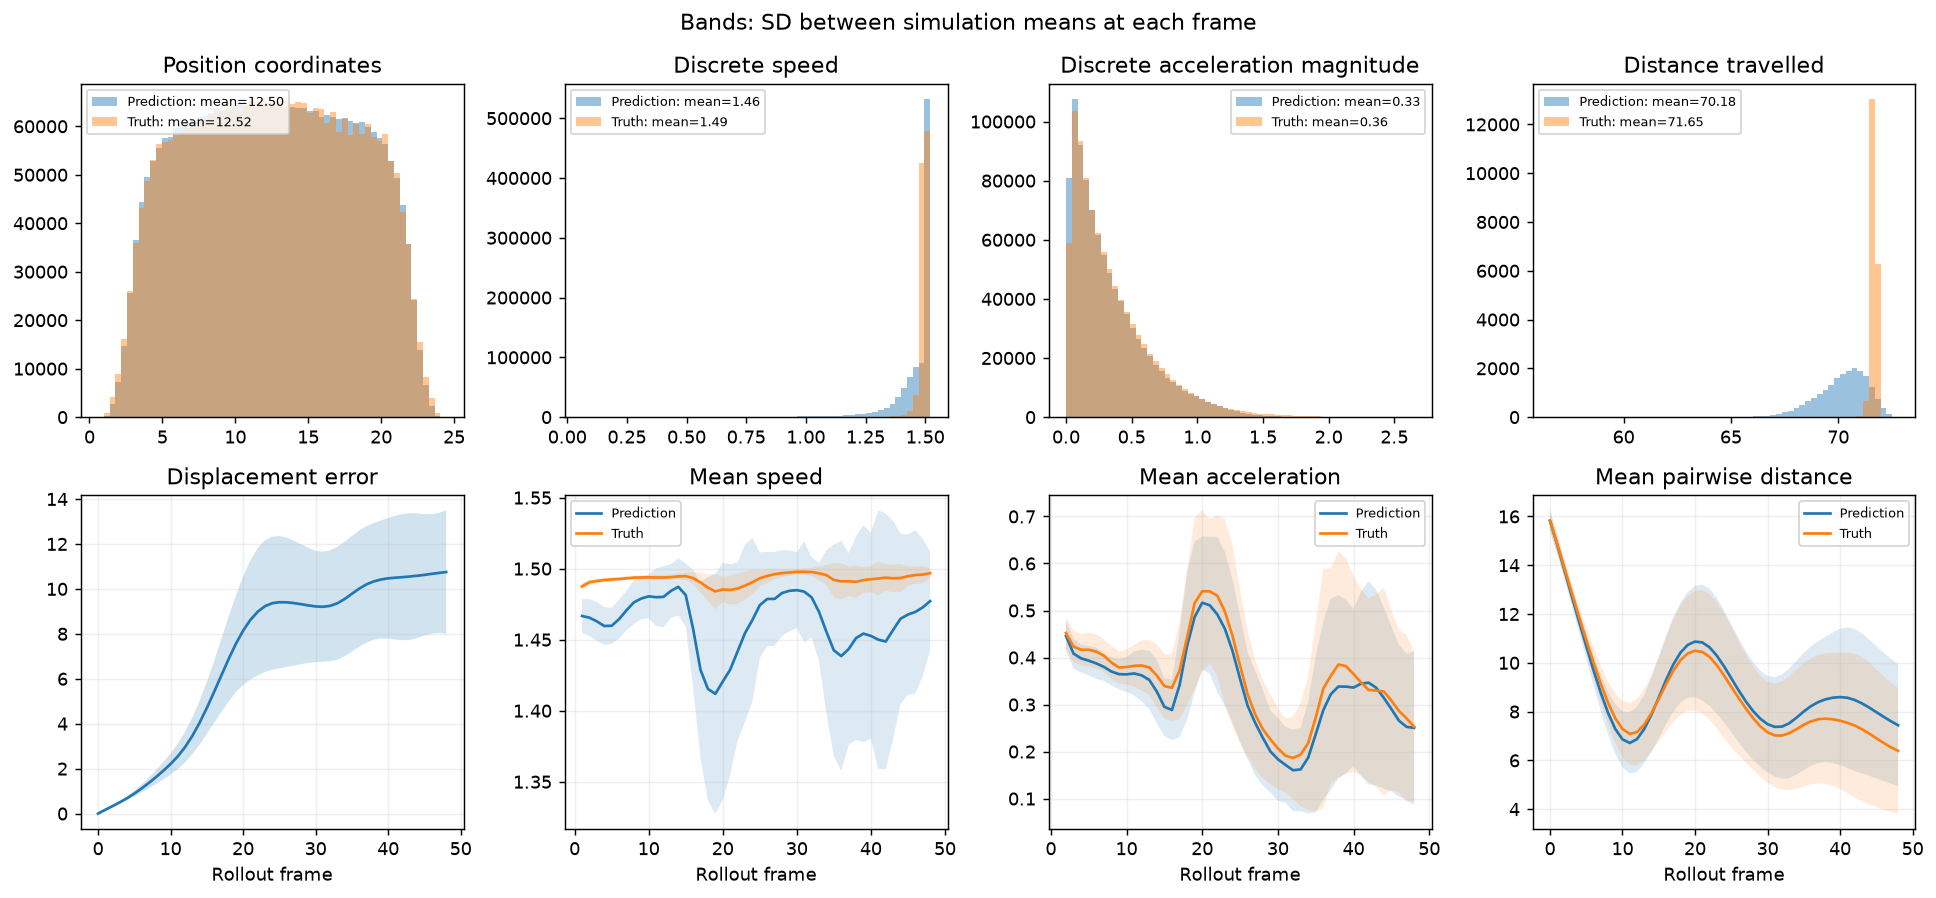

ADE (including initial frame): 6.9037
ADE (future frames only): 7.0475
FDE: 10.7516
Mean polarization: prediction=0.470, truth=0.495



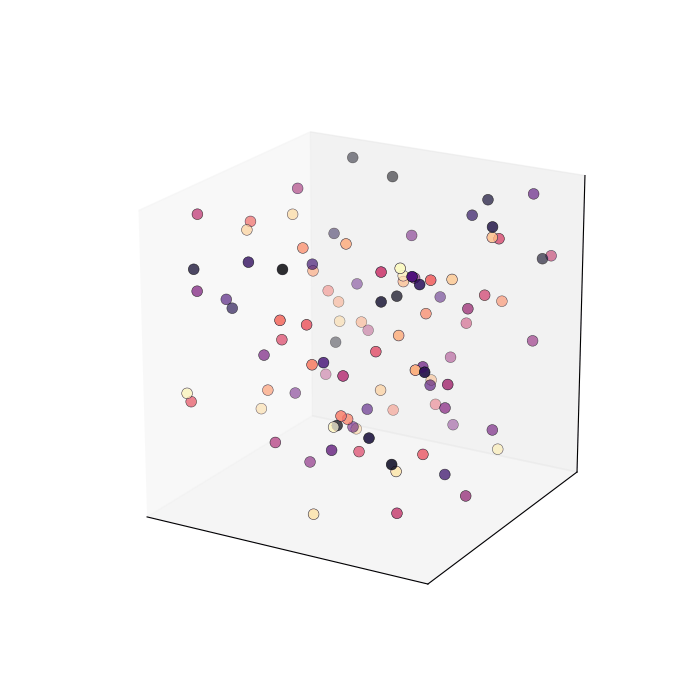
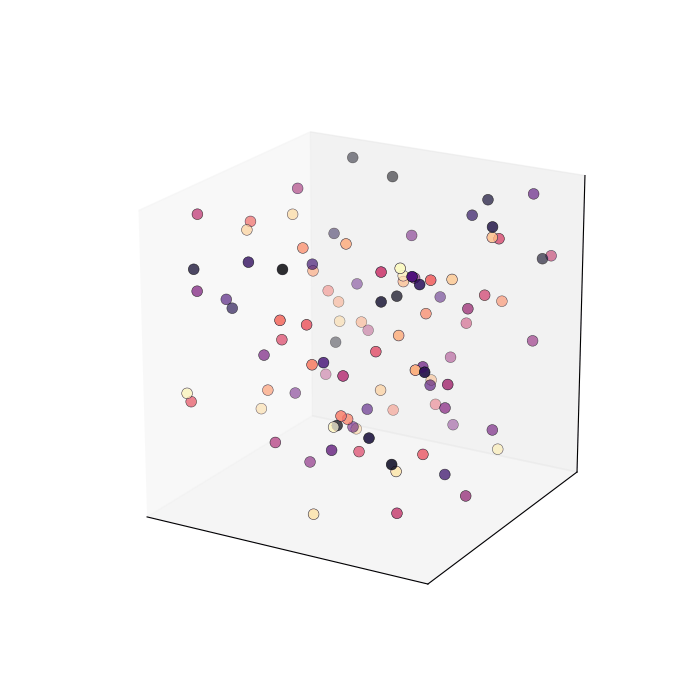

In [ ]:

# ---------------------------------------------------------------------------
# Collect the rollouts from trainer.predict (same order as the eval simulations)
# ---------------------------------------------------------------------------
rollout = {key: T.cat([r[key] for r in rollouts]).numpy() for key in rollouts[0]}
if (rollout["first_bad_frame"] >= 0).any():
    raise RuntimeError("Rollout diverged; inspect diagnostics. No failed trajectories are removed.")
eval_ids = traj_datamodule.val_ids if EVAL_SPLIT == "val" else traj_datamodule.test_ids
predicted_states = rollout["states"].transpose(0, 2, 1, 3)   # (S, T, N, 6)
raw_rollout_speeds = rollout["raw_speeds"].transpose(0, 2, 1)
ground_truth_states = traj_dataset.nodes[eval_ids].numpy()
predicted_positions = predicted_states[..., :3]
ground_truth_positions = ground_truth_states[..., :3]
print(f"Evaluating {len(eval_ids)} {EVAL_SPLIT} trajectories (no extra slicing)")
print(f"Raw rollout speeds above limit: {(raw_rollout_speeds > MAX_SPEED).mean():.1%}")
print("Raw speed percentiles [50,95,99]:", np.percentile(raw_rollout_speeds, [50, 95, 99]))

# ---------------------------------------------------------------------------
# Training curves
# ---------------------------------------------------------------------------
if loss_history.train_loss:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(loss_history.train_loss, label="Train (noisy inputs)")
    axes[0].plot(loss_history.val_loss, label="Validation (clean inputs)")
    axes[0].set(xlabel="Epoch", ylabel="Projected velocity MSE")
    axes[0].legend()
    epochs, ades = zip(*rollout_validation.history)
    axes[1].plot(epochs, ades)
    axes[1].set(xlabel="Epoch", ylabel="Validation rollout ADE (future frames)")
    plt.tight_layout(); plt.show()
# Optimized loss is projected MSE + RAW_LOSS_WEIGHT * raw MSE; the curves show projected MSE.

# ---------------------------------------------------------------------------
# Validation diagnostics: one-step metrics + clamp ON/OFF rollouts on ALL val sims
# ---------------------------------------------------------------------------
model.to(device)  # Lightning moves the module back to CPU after fit/predict
if RUN_DIAGNOSTICS:
    final_diagnostics = run_validation_diagnostics(model, datamodule)

# ---------------------------------------------------------------------------
# Discrete metrics (np.diff)
# ---------------------------------------------------------------------------
def calculate_kinematics(positions, dt=1.):
    """Discrete increments consistent with dataset velocities; omit self-pairs.

    Input (simulations, frames, particles, xyz). Velocity has frames-1 entries;
    acceleration has frames-2 entries. Path length sums segment lengths.
    Memory is O(simulations * frames * particles), not O(... * particles**2).
    """
    p = np.asarray(positions)
    if p.ndim != 4 or p.shape[-1] != 3 or p.shape[1] < 3 or p.shape[2] < 2:
        raise ValueError('Expected (S,T,N,3), with T>=3 and N>=2.')
    if dt <= 0:
        raise ValueError('dt must be positive.')
    increments = np.diff(p, axis=1)
    v = increments / dt
    a = np.diff(v, axis=1) / dt
    speed, acceleration = np.linalg.norm(v, axis=-1), np.linalg.norm(a, axis=-1)
    pair_sum = np.zeros(p.shape[:2], dtype=np.float64)
    n = p.shape[2]
    for i in range(n - 1):
        pair_sum += np.linalg.norm(p[:, :, i:i+1] - p[:, :, i+1:], axis=-1).sum(-1)
    pair_mean = pair_sum / (n * (n - 1) / 2)
    mean_v = v.mean(axis=2)
    polarization = np.linalg.norm(mean_v, axis=-1) / np.maximum(speed.mean(axis=2), 1e-8)
    radius = np.sqrt(((p - p.mean(axis=2, keepdims=True))**2).sum(-1).mean(-1))
    return {
        'vel_magnitudes': speed, 'acc_magnitudes': acceleration,
        'arc_lengths': np.linalg.norm(increments, axis=-1).sum(axis=1),
        'mean_vel_over_time': speed.mean(axis=(0, 2)),
        'mean_acc_over_time': acceleration.mean(axis=(0, 2)),
        'mean_dist_over_time': pair_mean.mean(axis=0),
        # Standard deviation BETWEEN simulations at EACH time, not over time.
        'std_vel_over_time': speed.mean(axis=2).std(axis=0),
        'std_acc_over_time': acceleration.mean(axis=2).std(axis=0),
        'std_dist_over_time': pair_mean.std(axis=0),
        'polarization': polarization, 'radius_of_gyration': radius,
        'velocity_times': np.arange(1, p.shape[1]),
        'acceleration_times': np.arange(2, p.shape[1]),
    }


def displacement_summary(predicted, truth):
    p, g = np.asarray(predicted), np.asarray(truth)
    if p.shape != g.shape or p.ndim != 4 or p.shape[1] < 2 or p.shape[-1] != 3:
        raise ValueError('Require matching (S,T,N,3) arrays with T>=2.')
    errors = np.linalg.norm(p - g, axis=-1)
    per_simulation = errors.mean(axis=2)
    return {
        'ADE': float(errors.mean()),  
        'ADE_future': float(errors[:, 1:].mean()),
        'FDE': float(errors[:, -1].mean()),
        'mean': per_simulation.mean(axis=0),
        'std': per_simulation.std(axis=0),
    }


def plot_comparison(predicted_positions, ground_truth_positions):
    if not (np.isfinite(predicted_positions).all() and np.isfinite(ground_truth_positions).all()):
        raise ValueError("Cannot evaluate non-finite trajectories.")
    pred = calculate_kinematics(predicted_positions)
    gt = calculate_kinematics(ground_truth_positions)
    errors = displacement_summary(predicted_positions, ground_truth_positions)
    fig, axs = plt.subplots(2, 4, figsize=(15, 7), dpi=130)
    histograms = [
        (predicted_positions, ground_truth_positions, "Position coordinates"),
        (pred["vel_magnitudes"], gt["vel_magnitudes"], "Discrete speed"),
        (pred["acc_magnitudes"], gt["acc_magnitudes"], "Discrete acceleration magnitude"),
        (pred["arc_lengths"], gt["arc_lengths"], "Distance travelled")]
    for ax, (a, b, title) in zip(axs[0], histograms):
        lo, hi = min(a.min(), b.min()), max(a.max(), b.max())
        bins = np.linspace(lo, max(hi, lo+1e-6), 61)
        for values, label, color in [(a, "Prediction", "tab:blue"), (b, "Truth", "tab:orange")]:
            ax.hist(values.ravel(), bins=bins, alpha=.45, color=color,
                    label=f"{label}: mean={values.mean():.2f}")
        ax.set_title(title); ax.legend(fontsize=7)
    time = np.arange(len(errors["mean"]))
    axs[1, 0].plot(time, errors["mean"], color="tab:blue")
    axs[1, 0].fill_between(time, np.maximum(0, errors["mean"]-errors["std"]),
                           errors["mean"]+errors["std"], alpha=.2)
    axs[1, 0].set_title("Displacement error")
    for ax, mean_key, std_key, time_key, title in [
        (axs[1, 1], "mean_vel_over_time", "std_vel_over_time", "velocity_times", "Mean speed"),
        (axs[1, 2], "mean_acc_over_time", "std_acc_over_time", "acceleration_times", "Mean acceleration"),
        (axs[1, 3], "mean_dist_over_time", "std_dist_over_time", None, "Mean pairwise distance")]:
        for values, label in [(pred, "Prediction"), (gt, "Truth")]:
            mean, std = values[mean_key], values[std_key]
            t = values[time_key] if time_key else np.arange(len(mean))
            ax.plot(t, mean, label=label)
            ax.fill_between(t, np.maximum(0, mean-std), mean+std, alpha=.15)
        ax.set_title(title); ax.legend(fontsize=7)
    for ax in axs[1]:
        ax.set_xlabel("Rollout frame"); ax.grid(alpha=.2)
    fig.suptitle("Bands: SD between simulation means at each frame")
    fig.tight_layout()
    return fig, errors, pred, gt

fig, metrics, pred, gt = plot_comparison(predicted_positions, ground_truth_positions)
plt.show()
print(f"ADE (including initial frame): {metrics['ADE']:.4f}")
print(f"ADE (future frames only): {metrics['ADE_future']:.4f}")
print(f"FDE: {metrics['FDE']:.4f}")
print(f"Mean polarization: prediction={pred['polarization'].mean():.3f}, "
      f"truth={gt['polarization'].mean():.3f}")


# ---------------------------------------------------------------------------
# GIFs: predicted vs ground-truth flock (first eval simulation)
# ---------------------------------------------------------------------------
def make_gif_dots(trajectory, filepath, limits, fps=10, dot_size=60, tracer_width=1.5):
    n_frames, n_boids, _ = trajectory.shape
    colors = plt.get_cmap("magma")(np.linspace(0, 1, n_boids))
    fig = plt.figure(figsize=(7, 7))
    ax = fig.add_subplot(111, projection="3d")
    ax.set_xlim(*limits[0]); ax.set_ylim(*limits[1]); ax.set_zlim(*limits[2])
    ax.set_box_aspect((1, 1, 1)); ax.view_init(elev=20, azim=-60)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    segments = np.stack([trajectory[:-1], trajectory[1:]], axis=2)
    scat = ax.scatter(*trajectory[0].T, s=dot_size, c=colors,
                      edgecolors="black", linewidths=.4)
    tracers = [ax.add_collection3d(Line3DCollection([], colors=colors[i], alpha=.5),
                                  autolim=False) for i in range(n_boids)]
    def draw_frame(frame):
        frame = min(frame, n_frames-1)
        scat._offsets3d = trajectory[frame].T
        for i, line in enumerate(tracers):
            line.set_segments(segments[:frame, i])
            line.set_linewidth(tracer_width)
        return [scat, *tracers]
    anim = animation.FuncAnimation(fig, draw_frame, frames=n_frames+2*fps,
                                   interval=1000/fps, blit=False)
    Path(filepath).parent.mkdir(parents=True, exist_ok=True)
    anim.save(str(filepath), writer="pillow", fps=fps)
    plt.close(fig)


def show_gifs_with_labels(filepaths, labels, width=400):
    # Embedded data works in Colab as well as local Jupyter.
    items = []
    for filepath, label in zip(filepaths, labels):
        encoded = base64.b64encode(Path(filepath).read_bytes()).decode("ascii")
        items.append(f'<div style="text-align:center"><img src="data:image/gif;base64,{encoded}" '
                     f'width="{width}"><br>{label}</div>')
    return HTML('<div style="display:flex;flex-wrap:wrap;gap:12px">'+''.join(items)+'</div>')

if MAKE_GIFS:
    both = np.concatenate([predicted_positions[0], ground_truth_positions[0]], axis=0)
    lower, upper = both.min(axis=(0, 1)), both.max(axis=(0, 1))
    center = (lower+upper)/2
    half_width = max(float((upper-lower).max())*.55, 1e-3)
    limits = np.stack([center-half_width, center+half_width], axis=1)
    files = ["figures/predicted_boids_v3.gif", "figures/true_boids_v3.gif"]
    make_gif_dots(predicted_positions[0], files[0], limits)
    make_gif_dots(ground_truth_positions[0], files[1], limits)
    display(show_gifs_with_labels(files, [f"Prediction ({EVAL_SPLIT})", "Ground truth"]))
